# Pemodelan & Simulasi Sistem Dinamik: Pengisian dan Pengurasan Air Kolam Ikan
Mata kuliah Pemodelan dan Simulasi (MOSI) | Nama: Fadhly Muhammad Fachrezi | NIM: 301240001

## a. Deskripsi Studi Kasus
Kolam ikan berukuran 3 m x 2 m (A = 6 m2). Tinggi air **h(t)** (m) dipengaruhi **input** berupa kran pengisian (u_i, %) dan **output** berupa kran pengurasan (u_o, %). Nilai kran 0% = tertutup, 100% = terbuka penuh.
Tujuan: mengetahui respon tinggi air terhadap pengisian dan pengurasan agar air tidak kosong atau meluap.

## b. Persamaan yang digunakan
Kesetimbangan massa: dm/dt = dm_i/dt - dm_o/dt, dengan m = rho A h, sehingga:

| No | Skenario | Persamaan |
|---|---|---|
| 1 | Pengisian saja (padanan Program 1) | dh/dt = c u / (rho A) |
| 2 | Pengisian + pengurasan (padanan Program 2) | dh/dt = c (u_i - u_o) / (rho A) |
| 3 | Pengurasan alami, variasi k (padanan Contoh 2) | dh/dt = -k h |
| 4 | Pengisian step + lubang pembuangan (padanan Contoh 3) | 20 dh/dt = -h + 0.6 u/100 |

rho = 1000 kg/m3, A = 6 m2, c = 1.8 kg/menit per % bukaan (100% = 180 kg/menit = 3 L/detik).

## c. Pemodelan menggunakan Python
### Skenario 1: Pengisian saja (ODEINT)

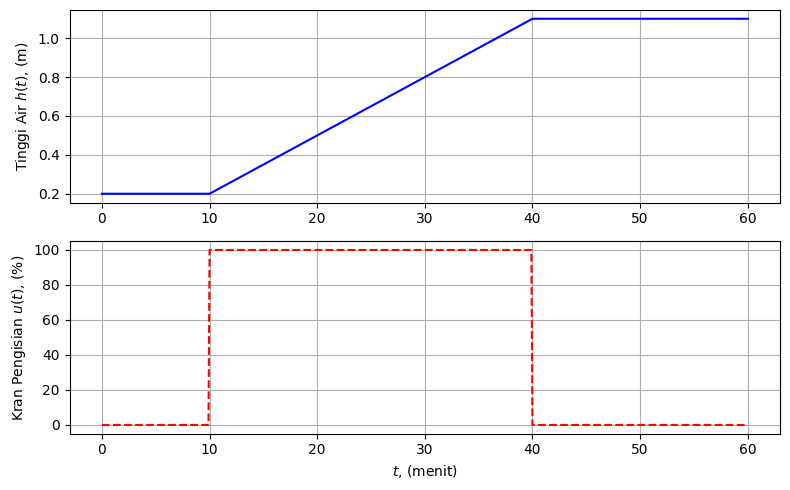

Tinggi air akhir: 1.100 m


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import odeint

# ===== Skenario 1: PENGISIAN saja (kran pengurasan tertutup) =====
def kolam(h, t, c, valve):
    rho = 1000.0               # massa jenis air (kg/m^3)
    A = 6.0                    # luas permukaan kolam 3 m x 2 m (m^2)
    dhdt = (c / (rho * A)) * valve      # dh/dt = c*u/(rho*A)  (m/menit)
    return dhdt

ts = np.linspace(0, 60, 601)   # 60 menit, setiap 0.1 menit
c = 1.8                        # koefisien kran (kg/menit per % bukaan)
u = np.zeros(601)              # u = bukaan kran pengisian (%)
u[100:400] = 100.0             # kran pengisian dibuka penuh menit ke-10 s.d. ke-40

h0 = 0.2                       # tinggi air awal (m)
z = np.zeros(601); z[0] = h0

for i in range(600):
    valve = u[i]
    y = odeint(kolam, h0, [0, 0.1], args=(c, valve))
    h0 = y[-1][0]              # ambil titik terakhir
    z[i+1] = h0

plt.figure(figsize=(8, 5))
plt.subplot(2, 1, 1)
plt.plot(ts, z, 'b-')
plt.ylabel('Tinggi Air $h(t)$, (m)'); plt.grid()
plt.subplot(2, 1, 2)
plt.plot(ts, u, 'r--')
plt.ylabel('Kran Pengisian $u(t)$, (%)'); plt.xlabel('$t$, (menit)'); plt.grid()
plt.tight_layout(); plt.show()
print('Tinggi air akhir: %.3f m' % z[-1])

In [ ]:
# Perhitungan manual Skenario 1
interval = [(0,10,0),(10,40,100),(40,60,0)]
rows, h = [], 0.2
for a, b, uu in interval:
    laju = c * uu / (1000.0 * 6.0)       # m/menit
    dh = laju * (b - a)
    h = h + dh
    rows.append([f'{a}-{b}', uu, round(laju,4), b-a, round(dh,3), round(h,3)])
tabel1 = pd.DataFrame(rows, columns=['Interval (menit)','u (%)','dh/dt (m/menit)','Durasi (menit)','Delta h (m)','h (m)'])
print(tabel1.to_string(index=False))

Interval (menit)  u (%)  dh/dt (m/menit)  Durasi (menit)  Delta h (m)  h (m)
            0-10      0             0.00              10          0.0    0.2
           10-40    100             0.03              30          0.9    1.1
           40-60      0             0.00              20          0.0    1.1


### Skenario 1 (GEKKO)
Jalankan dulu: `!pip install gekko`

In [ ]:
!pip install gekko -q

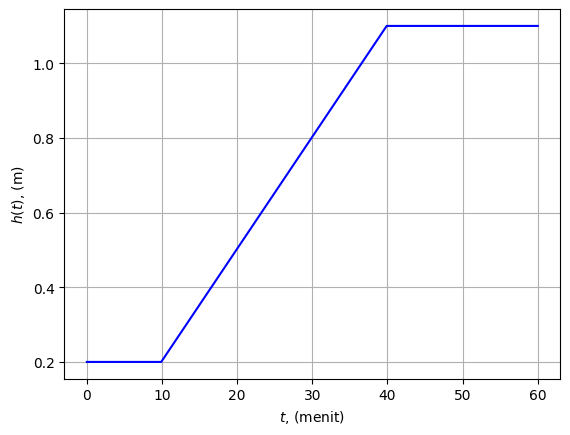

In [ ]:
# GEKKO (jalankan di Colab: !pip install gekko)
from gekko import GEKKO

m = GEKKO(remote=False)
m.time = np.linspace(0, 60, 601)
ustep = np.zeros(601); ustep[100:] = 100.0; ustep[400:] = 0.0
u = m.Param(value=ustep)
h = m.Var(0.2)
m.Equation(h.dt() == (1.8 / (1000.0 * 6.0)) * u)
m.options.IMODE = 4
m.solve(disp=False)

plt.plot(m.time, h.value, 'b-')
plt.xlabel('$t$, (menit)'); plt.ylabel('$h(t)$, (m)'); plt.grid(); plt.show()

### Skenario 2: Pengisian + pengurasan (ODEINT)

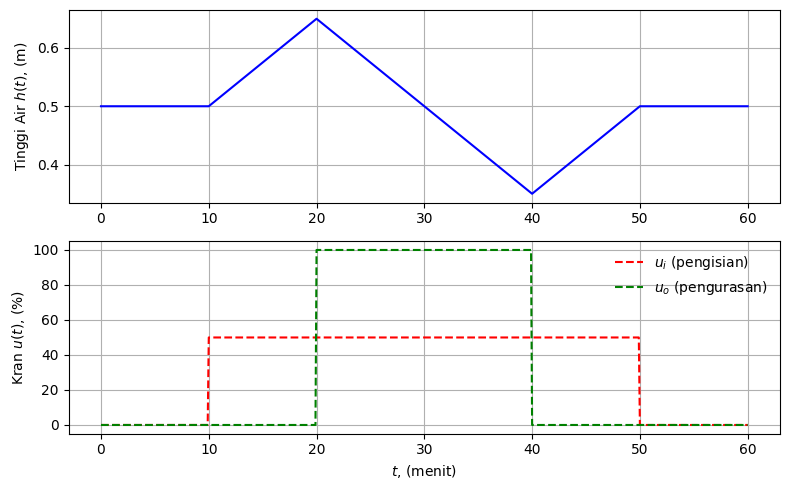

Tinggi minimum: 0.350 m | akhir: 0.500 m


In [ ]:
# ===== Skenario 2: PENGISIAN dan PENGURASAN (dua kran) =====
def kolam2(h, t, c, valve_i, valve_o):
    rho = 1000.0
    A = 6.0
    dhdt = (c / (rho * A)) * (valve_i - valve_o)   # dh/dt = c(ui - uo)/(rho*A)
    return dhdt

ui = np.zeros(601); ui[100:500] = 50.0     # pengisian 50% menit 10-50
uo = np.zeros(601); uo[200:400] = 100.0    # pengurasan 100% menit 20-40

h0 = 0.5
z2 = np.zeros(601); z2[0] = h0
for i in range(600):
    y = odeint(kolam2, h0, [0, 0.1], args=(c, ui[i], uo[i]))
    h0 = y[-1][0]
    z2[i+1] = h0

plt.figure(figsize=(8, 5))
plt.subplot(2, 1, 1)
plt.plot(ts, z2, 'b-')
plt.ylabel('Tinggi Air $h(t)$, (m)'); plt.grid()
plt.subplot(2, 1, 2)
plt.plot(ts, ui, 'r--', label='$u_i$ (pengisian)')
plt.plot(ts, uo, 'g--', label='$u_o$ (pengurasan)')
plt.ylabel('Kran $u(t)$, (%)'); plt.xlabel('$t$, (menit)')
plt.legend(frameon=False); plt.grid()
plt.tight_layout(); plt.show()
print('Tinggi minimum: %.3f m | akhir: %.3f m' % (z2.min(), z2[-1]))

In [ ]:
# Perhitungan manual Skenario 2
interval = [(0,10,0,0),(10,20,50,0),(20,40,50,100),(40,50,50,0),(50,60,0,0)]
rows, h = [], 0.5
for a, b, ui_, uo_ in interval:
    laju = c * (ui_ - uo_) / (1000.0 * 6.0)
    dh = laju * (b - a)
    h = h + dh
    rows.append([f'{a}-{b}', ui_, uo_, round(laju,4), round(dh,3), round(h,3)])
tabel2 = pd.DataFrame(rows, columns=['Interval (menit)','ui (%)','uo (%)','dh/dt (m/menit)','Delta h (m)','h (m)'])
print(tabel2.to_string(index=False))

Interval (menit)  ui (%)  uo (%)  dh/dt (m/menit)  Delta h (m)  h (m)
            0-10       0       0            0.000         0.00   0.50
           10-20      50       0            0.015         0.15   0.65
           20-40      50     100           -0.015        -0.30   0.35
           40-50      50       0            0.015         0.15   0.50
           50-60       0       0            0.000         0.00   0.50


### Skenario 2 (GEKKO)

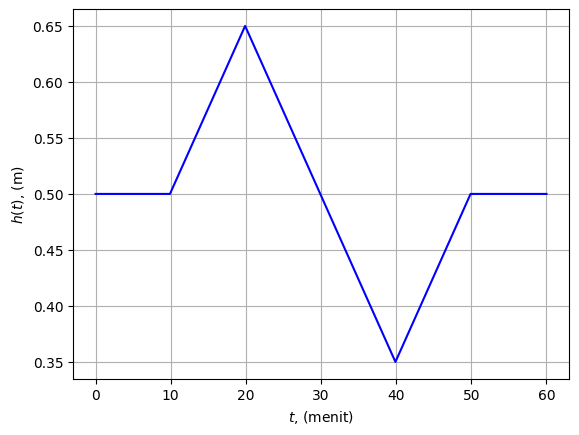

In [ ]:
m = GEKKO(remote=False)
m.time = np.linspace(0, 60, 601)
ui_s = np.zeros(601); ui_s[100:500] = 50.0
uo_s = np.zeros(601); uo_s[200:400] = 100.0
ui_g = m.Param(value=ui_s)
uo_g = m.Param(value=uo_s)
h = m.Var(0.5)
m.Equation(h.dt() == (1.8 / (1000.0 * 6.0)) * (ui_g - uo_g))
m.options.IMODE = 4
m.solve(disp=False)

plt.plot(m.time, h.value, 'b-')
plt.xlabel('$t$, (menit)'); plt.ylabel('$h(t)$, (m)'); plt.grid(); plt.show()

### Skenario 3: Pengurasan alami dengan variasi k (ODEINT)

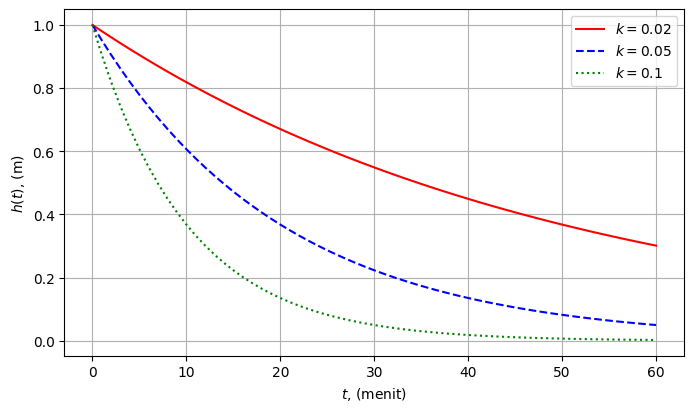

In [ ]:
# ===== Skenario 3: PENGURASAN ALAMI lewat lubang pembuangan, variasi k (args) =====
def kuras(h, t, k):
    dhdt = -k * h                      # dh/dt = -k h
    return dhdt

h0 = 1.0                               # kolam penuh 1.0 m
t3 = np.linspace(0, 60, 61)

k = 0.02
h_a = odeint(kuras, h0, t3, args=(k,))
k = 0.05
h_b = odeint(kuras, h0, t3, args=(k,))
k = 0.1
h_c = odeint(kuras, h0, t3, args=(k,))

plt.figure(figsize=(8, 4.5))
plt.plot(t3, h_a, 'r-',  label='$k=0.02$')
plt.plot(t3, h_b, 'b--', label='$k=0.05$')
plt.plot(t3, h_c, 'g:',  label='$k=0.1$')
plt.xlabel('$t$, (menit)'); plt.ylabel('$h(t)$, (m)')
plt.legend(); plt.grid(); plt.show()

In [ ]:
# Perhitungan manual Skenario 3 (k = 0.05, Euler dt = 5 menit)
k, dt, h_e = 0.05, 5.0, 1.0
rows = []
for n in range(7):
    t_now = n * dt
    h_an = 1.0 * np.exp(-k * t_now)
    rows.append([t_now, round(h_e,4), round(-k*h_e,4), round(h_an,4), round(abs(h_e-h_an),4)])
    h_e = h_e + dt * (-k * h_e)
tabel3 = pd.DataFrame(rows, columns=['t (menit)','h Euler','dh/dt = -kh','h analitik','|error|'])
print(tabel3.to_string(index=False))

 t (menit)  h Euler  dh/dt = -kh  h analitik  |error|
       0.0   1.0000      -0.0500      1.0000   0.0000
       5.0   0.7500      -0.0375      0.7788   0.0288
      10.0   0.5625      -0.0281      0.6065   0.0440
      15.0   0.4219      -0.0211      0.4724   0.0505
      20.0   0.3164      -0.0158      0.3679   0.0515
      25.0   0.2373      -0.0119      0.2865   0.0492
      30.0   0.1780      -0.0089      0.2231   0.0452


### Skenario 3 (GEKKO)

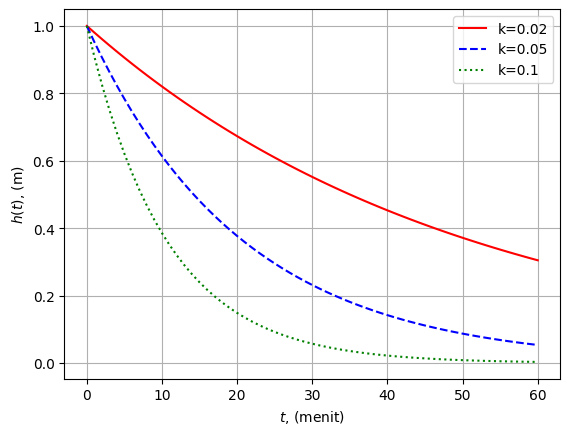

In [ ]:
m = GEKKO(remote=False)
k = m.Param()
h = m.Var(1.0)
m.Equation(h.dt() == -k * h)
m.time = np.linspace(0, 60, 61)
m.options.IMODE = 4
m.options.TIME_SHIFT = 0

k.value = 0.02; m.solve(disp=False); plt.plot(m.time, h.value, 'r-',  label='k=0.02')
k.value = 0.05; m.solve(disp=False); plt.plot(m.time, h.value, 'b--', label='k=0.05')
k.value = 0.1;  m.solve(disp=False); plt.plot(m.time, h.value, 'g:',  label='k=0.1')
plt.xlabel('$t$, (menit)'); plt.ylabel('$h(t)$, (m)'); plt.legend(); plt.grid(); plt.show()

### Skenario 4: Pengisian step + lubang pembuangan (ODEINT)

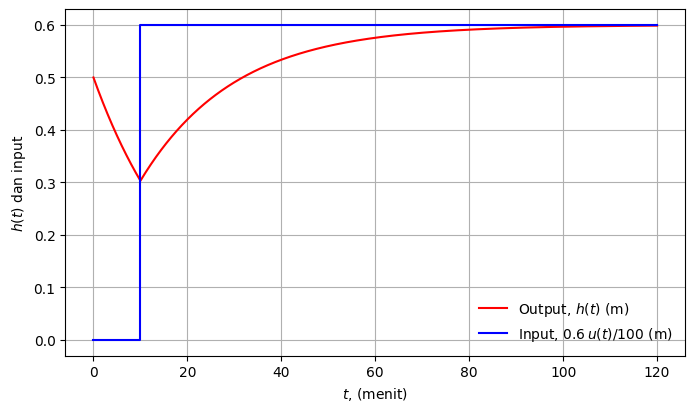

h pada t = 10 menit: 0.303 m | h akhir: 0.599 m


In [ ]:
# ===== Skenario 4: pengisian step + lubang pembuangan (padanan Contoh 3) =====
# 20 dh/dt = -h + 0.6*u/100   ->   tau = 20 menit, h_inf = 0.6 m saat u = 100%
def kolam4(h, t):
    u = 0.0 if t < 10.0 else 100.0         # kran pengisian dibuka penuh pada menit ke-10
    dhdt = (-h + 0.6 * u / 100.0) / 20.0
    return dhdt

h0 = 0.5
t4 = np.linspace(0, 120, 1201)
h4 = odeint(kolam4, h0, t4)[:, 0]

plt.figure(figsize=(8, 4.5))
plt.plot(t4, h4, 'r-', label='Output, $h(t)$ (m)')
plt.plot([0, 10, 10, 120], [0, 0, 0.6, 0.6], 'b-', label='Input, $0.6\\,u(t)/100$ (m)')
plt.xlabel('$t$, (menit)'); plt.ylabel('$h(t)$ dan input')
plt.legend(loc='best', frameon=False); plt.grid(); plt.show()
print('h pada t = 10 menit: %.3f m | h akhir: %.3f m' % (h4[100], h4[-1]))

In [ ]:
# Perhitungan manual Skenario 4 (Euler dt = 5 menit, mulai t = 10)
tau, h_inf, dt = 20.0, 0.6, 5.0
h_e = 0.5 * np.exp(-10/tau)               # tinggi pada t = 10 (0.303 m)
rows = []
for n in range(7):
    t_now = 10 + n*dt
    h_an = h_inf + (0.5*np.exp(-10/tau) - h_inf) * np.exp(-(t_now-10)/tau)
    rows.append([t_now, round(h_e,4), round((h_inf-h_e)/tau,4), round(h_an,4), round(abs(h_e-h_an),4)])
    h_e = h_e + dt * (h_inf - h_e) / tau
tabel4 = pd.DataFrame(rows, columns=['t (menit)','h Euler','dh/dt','h analitik','|error|'])
print(tabel4.to_string(index=False))

 t (menit)  h Euler  dh/dt  h analitik  |error|
      10.0   0.3033 0.0148      0.3033   0.0000
      15.0   0.3774 0.0111      0.3689   0.0085
      20.0   0.4331 0.0083      0.4200   0.0131
      25.0   0.4748 0.0063      0.4598   0.0150
      30.0   0.5061 0.0047      0.4908   0.0153
      35.0   0.5296 0.0035      0.5150   0.0146
      40.0   0.5472 0.0026      0.5338   0.0134


### Skenario 4 (GEKKO)

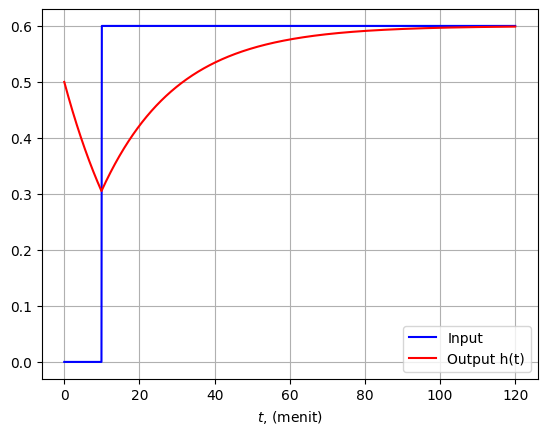

In [ ]:
m = GEKKO(remote=False)
m.time = np.linspace(0, 120, 1201)
ustep = np.zeros(1201); ustep[100:] = 0.6     # input 0.6*u/100 dengan u=100% mulai menit 10
u = m.Param(value=ustep)
h = m.Var(0.5)
m.Equation(20 * h.dt() == -h + u)
m.options.IMODE = 4
m.solve(disp=False)

plt.plot(m.time, u, 'b-', label='Input')
plt.plot(m.time, h, 'r-', label='Output h(t)')
plt.xlabel('$t$, (menit)'); plt.legend(); plt.grid(); plt.show()

## d. Penjelasan koding
- `kolam(h, t, c, valve)` mengembalikan dh/dt; `args` membawa parameter dan bukaan kran.
- Array `u` berisi bukaan kran tiap 0.1 menit; `u[100:400] = 100` berarti menit ke-10 sampai ke-40.
- Loop `for` memanggil `odeint` per langkah 0.1 menit dan memakai hasil terakhir sebagai kondisi awal berikutnya.
- Skenario 2 memakai dua input (ui, uo) dengan selisih (ui - uo).
- Skenario 3: nilai k dikirim lewat `args` sehingga mudah divariasikan.
- Skenario 4: `if t < 10` membuat input step.
- GEKKO: `m.Var` = variabel state, `m.Param` = input, `m.Equation(h.dt() == -h + u)` = persamaan, `IMODE = 4` = simulasi dinamik.

## e & f. Grafik dan penjelasan: lihat laporan (.docx)

Link GitHub:https://github.com/Fachreziq/Pemodelan-Kolam-Ikan
Link YouTube:https://youtu.be/0pfCjh7eALc?si=xgKGd_u4iuoyzHmZ